In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append("../src")

In [4]:
DATA_DIR = "../data/troupe/TLSC"

In [5]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  11


In [6]:
t_id = 0
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	272
Total number of nodes:	543
Rooted:	Yes
Most distant node:	AATGGCTGTAATGATG-1
Max. distance:	0.994189


In [7]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i + 1
    
    G.add_node(0, name="root", dist=0.0, is_leaf=False)

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, length=node.dist)
        else:
            G.add_edge(0, node_id, length=node.dist)

    G.graph["root"] = 0

    return G

In [8]:
T = ete_to_nx(t)
T

In [9]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False}, 1: {'name': '', 'dist': 0.005811072964601553, 'is_leaf': False}, 2: {'name': 'node_40', 'dist': 0.005811072975567898, 'is_leaf': False}, 3: {'name': 'node_78', 'dist': 0.0058110729830772225, 'is_leaf': False}, 4: {'name': 'node_100', 'dist': 0.005811072997589817, 'is_leaf': False}, 5: {'name': 'node_172', 'dist': 0.005811072961882457, 'is_leaf': False}, 6: {'name': 'node_332', 'dist': 0.005811072951924963, 'is_leaf': False}, 7: {'name': 'node_452', 'dist': 0.005811072945886988, 'is_leaf': False}, 8: {'name': 'node_458', 'dist': 0.00581107294701236, 'is_leaf': False}, 9: {'name': 'node_520', 'dist': 0.2005793007284973, 'is_leaf': False}, 10: {'name': 'node_528', 'dist': 0.23005013337846075, 'is_leaf': False}, 11: {'name': 'AAACGAAGTCCTGGTG-1', 'dist': 0.5170709091515836, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteDermo'}, 12: {'name': 'CTCGAGGCACTGAGGA-1', 'dist': 0.5170709091515836

In [10]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'length': 0.005811072964601553}), (1, 2, {'length': 0.005811072975567898}), (1, 505, {'length': 0.07834987421325626}), (2, 3, {'length': 0.0058110729830772225}), (2, 466, {'length': 0.3537442625810779}), (3, 4, {'length': 0.005811072997589817}), (3, 443, {'length': 0.0871950463235649}), (4, 5, {'length': 0.005811072961882457}), (4, 372, {'length': 0.00581107301562022}), (5, 6, {'length': 0.005811072951924963}), (5, 205, {'length': 0.005811073011180858}), (6, 7, {'length': 0.005811072945886988}), (6, 86, {'length': 0.005811073126349352}), (7, 8, {'length': 0.00581107294701236}), (7, 81, {'length': 0.5179934031330352}), (8, 9, {'length': 0.2005793007284973}), (8, 20, {'length': 0.005811072949453414}), (9, 10, {'length': 0.23005013337846075}), (9, 13, {'length': 0.10239964351456428}), (10, 11, {'length': 0.5170709091515836}), (10, 12, {'length': 0.5170709091515836}), (13, 14, {'length': 0.3560940637939932}), (13, 17, {'length': 0.10856481752108918}), (14, 15, {'le

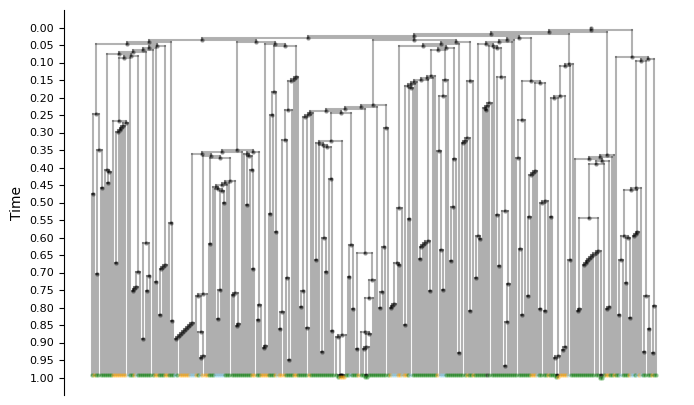

In [11]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [12]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [13]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [14]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9941889269497115 1.0


In [15]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [16]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [17]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['length']
        
        excess = dist - 1.0
        T[parent][leaf]['length'] = max(edge_length - excess, 0)  # avoid negative lengths

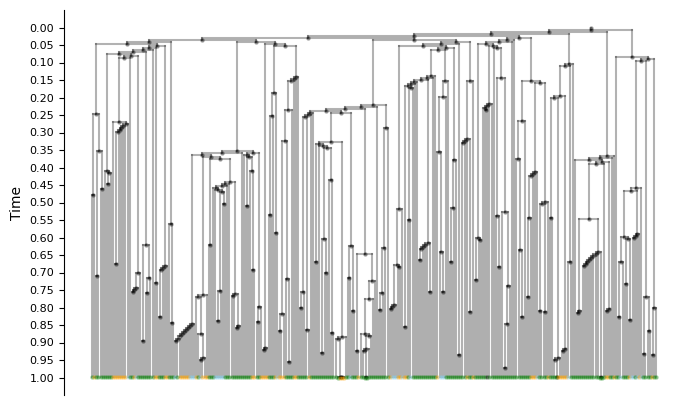

In [18]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [19]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [20]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

In [21]:
T = enforce_min_edge_length(T, root=T.graph['root'], min_length=0.001)

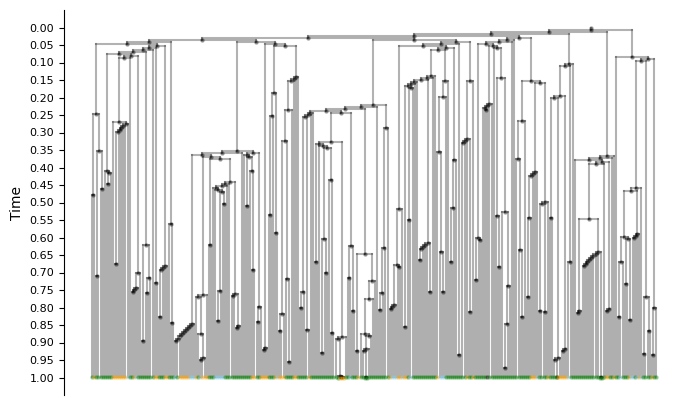

In [22]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [23]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [24]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999000000000001 1.0


In [25]:
EPS = 1e-4
scale = (1 - EPS) / max_dist  # scale to make the min leaf at 1

In [26]:
scale

0.9999

In [27]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [28]:
scale

0.9999

In [29]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

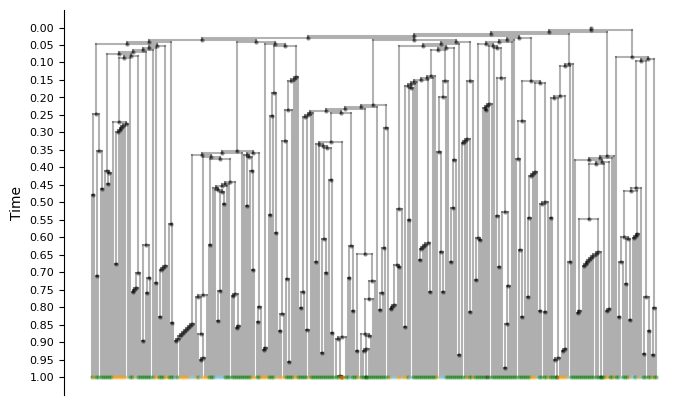

In [30]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [31]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'Somite': 180, 'NMPs': 62, 'NeuralTube': 29, 'PCGLC': 1})

In [32]:
def extract_kept_subtrees(
    graph,
    keep_states=("Somite", "NeuralTube", "NMPs"),
    root=None,
    state_attribute="state",
):
    """Extract maximal subtrees whose leaves all have an allowed state."""
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError("Expected a directed acyclic tree")

    if root is None:
        root = graph.graph.get("root")
    if root is None:
        roots = [node for node, degree in graph.in_degree() if degree == 0]
        if len(roots) != 1:
            raise ValueError("Specify root when the graph does not have exactly one root")
        root = roots[0]
    if root not in graph:
        raise ValueError(f"Root node {root!r} is not in the graph")

    allowed_states = set(keep_states)
    subtrees = []

    def make_subtree(nodes, subtree_root):
        subtree = graph.subgraph(nodes).copy()
        subtree.graph.update(graph.graph)
        subtree.graph["root"] = subtree_root
        return subtree

    def classify(node):
        children = list(graph.successors(node))
        if not children:
            is_good_leaf = graph.nodes[node].get(state_attribute) in allowed_states
            return is_good_leaf, {node} if is_good_leaf else set(), []

        child_results = []
        nested_subtrees = []
        for child in children:
            child_is_good, child_nodes, child_subtrees = classify(child)
            child_results.append((child, child_is_good, child_nodes))
            nested_subtrees.extend(child_subtrees)

        good_children = [result for result in child_results if result[1]]
        if len(good_children) == len(children):
            kept_nodes = {node}
            for _, _, child_nodes in good_children:
                kept_nodes.update(child_nodes)
            return True, kept_nodes, nested_subtrees

        if good_children:
            kept_nodes = {node}
            for _, _, child_nodes in good_children:
                kept_nodes.update(child_nodes)
            nested_subtrees.append(make_subtree(kept_nodes, node))

        return False, set(), nested_subtrees

    whole_tree_is_good, whole_tree_nodes, nested_subtrees = classify(root)
    if whole_tree_is_good:
        return [make_subtree(whole_tree_nodes, root)]
    return nested_subtrees

In [33]:
from collections import Counter

T_target_subtrees = extract_kept_subtrees(T)
allowed_leaf_states = {"Somite", "NeuralTube", "NMPs"}
source_kept_leaves = Counter(
    node
    for node, data in T.nodes(data=True)
    if T.out_degree(node) == 0 and data.get("state") in allowed_leaf_states
)
extracted_leaves = Counter(
    node
    for subtree in T_target_subtrees
    for node, data in subtree.nodes(data=True)
    if subtree.out_degree(node) == 0
)
assert extracted_leaves == source_kept_leaves

for index, subtree in enumerate(T_target_subtrees):
    leaf_states = {
        data.get("state")
        for node, data in subtree.nodes(data=True)
        if subtree.out_degree(node) == 0
    }
    assert leaf_states <= allowed_leaf_states
    print(
        f"Subtree {index}: root={subtree.graph['root']}, "
        f"nodes={subtree.number_of_nodes()}, edges={subtree.number_of_edges()}, "
        f"leaves={sum(1 for node in subtree if subtree.out_degree(node) == 0)}, "
        f"leaf states={sorted(leaf_states)}"
    )
print(f"Extracted {len(T_target_subtrees)} subtrees")

Subtree 0: root=388, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 1: root=386, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 2: root=385, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 3: root=384, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 4: root=383, nodes=18, edges=17, leaves=9, leaf states=['Somite']
Subtree 5: root=375, nodes=8, edges=7, leaves=4, leaf states=['Somite']
Subtree 6: root=374, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 7: root=373, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 8: root=372, nodes=32, edges=31, leaves=16, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 9: root=4, nodes=368, edges=367, leaves=184, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 10: root=3, nodes=24, edges=23, leaves=12, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 11: root=2, nodes=40, edges=39, leaves=20, leaf states=['NMPs', 'Somite']
Subtree 12: root=1, nodes=40, edges=39, leaves=20

Plotting subtree 1/13 (root=388)


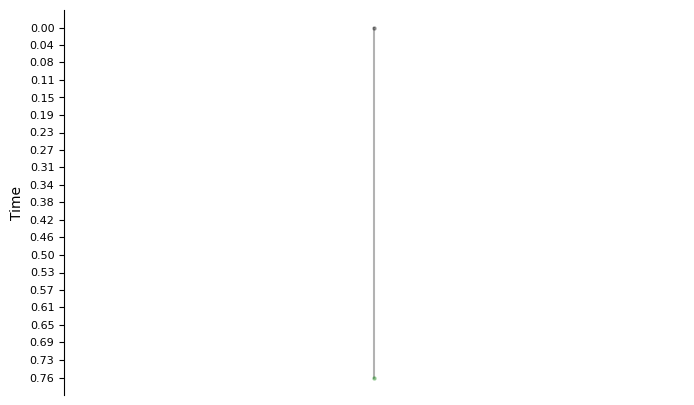

Plotting subtree 2/13 (root=386)


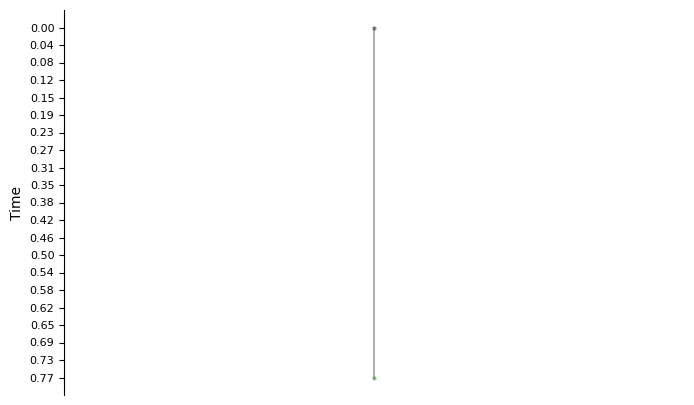

Plotting subtree 3/13 (root=385)


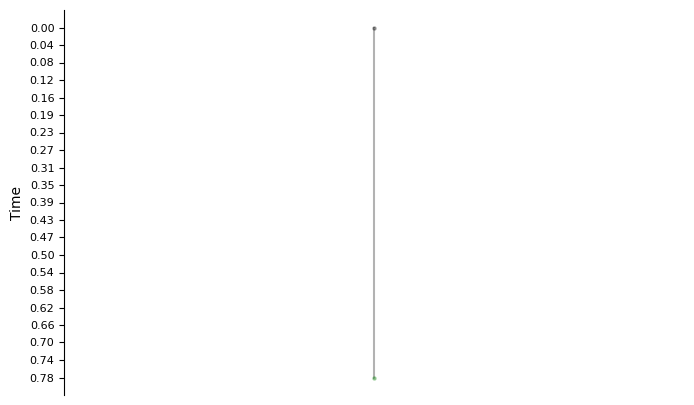

Plotting subtree 4/13 (root=384)


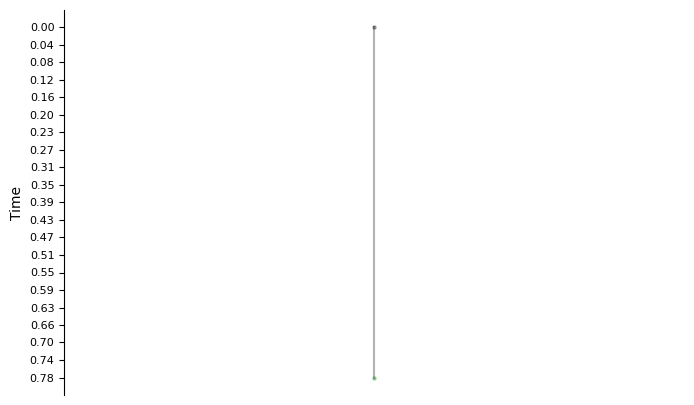

Plotting subtree 5/13 (root=383)


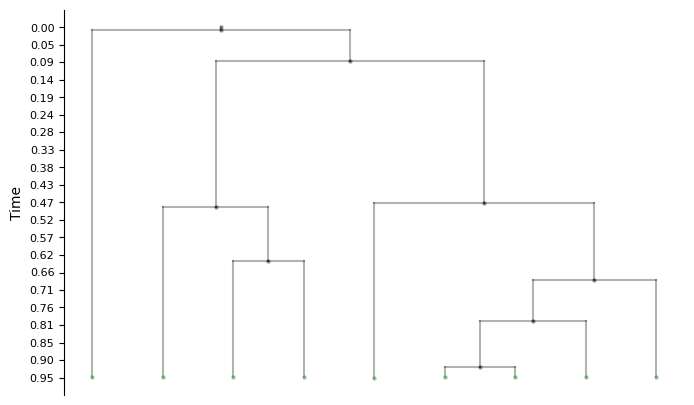

Plotting subtree 6/13 (root=375)


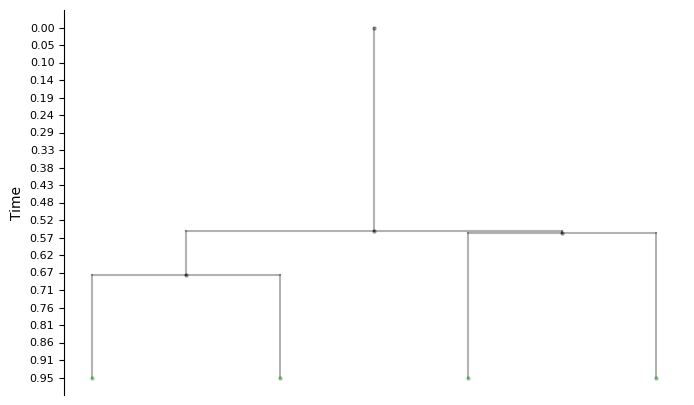

Plotting subtree 7/13 (root=374)


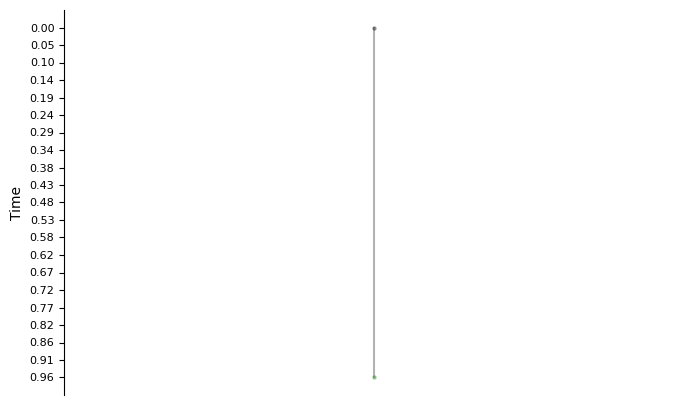

Plotting subtree 8/13 (root=373)


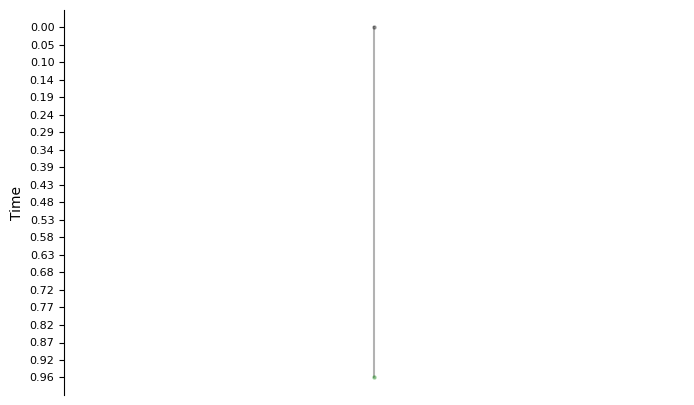

Plotting subtree 9/13 (root=372)


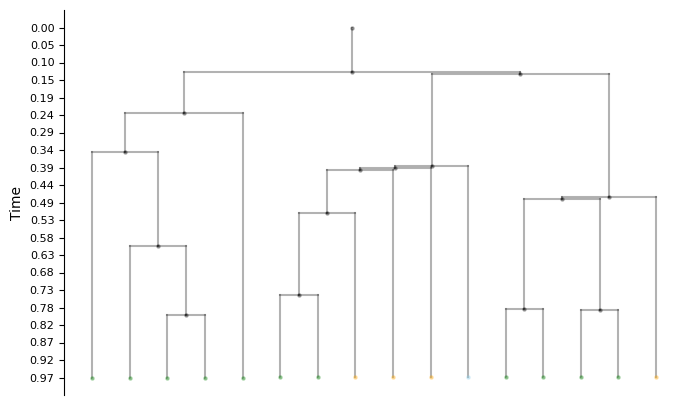

Plotting subtree 10/13 (root=4)


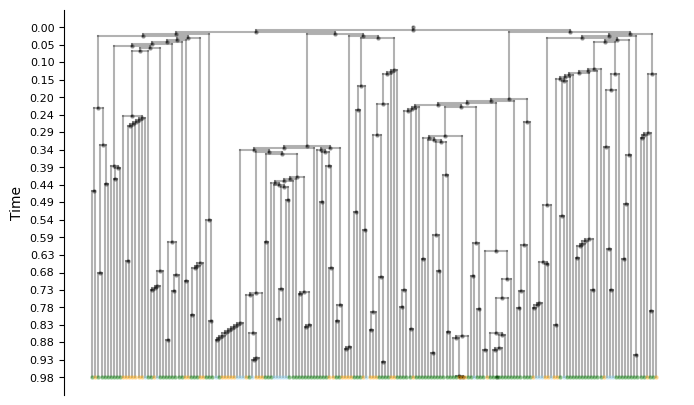

Plotting subtree 11/13 (root=3)


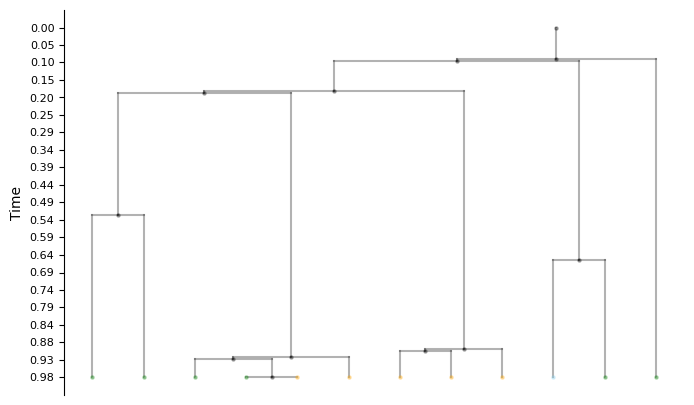

Plotting subtree 12/13 (root=2)


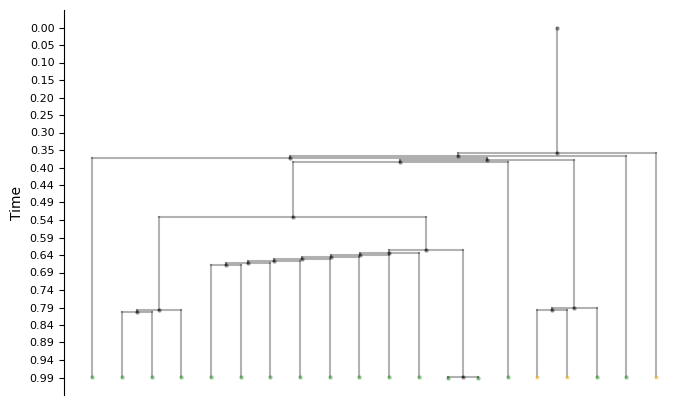

Plotting subtree 13/13 (root=1)


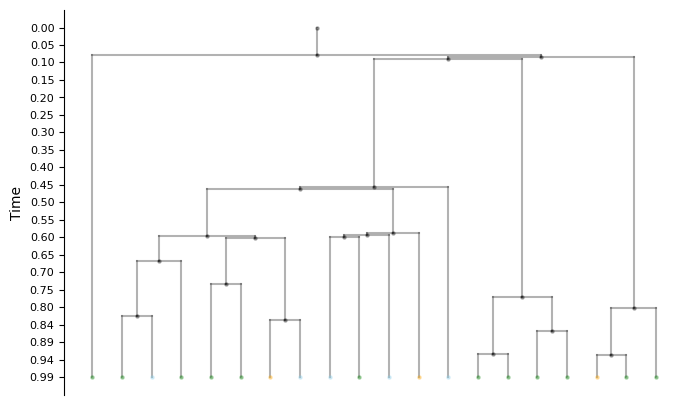

In [34]:
for index, subtree in enumerate(T_target_subtrees, start=1):
    print(f"Plotting subtree {index}/{len(T_target_subtrees)} (root={subtree.graph['root']})")
    draw_ultrametric_tree(
        subtree,
        root=subtree.graph["root"],
        add_labels=False,
    )

In [35]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path(DATA_DIR).resolve().parents[2]))
from src.dataprocessor import export_tree


state_id_by_label = {
    "NMPs": 0,
    "Somite": 1,
    "NeuralTube": 2,
}


def relabel_subtree_root_first(subtree):
    subtree_root = subtree.graph["root"]
    node_order = [subtree_root] + [
        node
        for node in nx.dfs_preorder_nodes(subtree, source=subtree_root)
        if node != subtree_root
    ]
    node_mapping = {node: index for index, node in enumerate(node_order)}
    relabeled = nx.relabel_nodes(subtree, node_mapping, copy=True)
    relabeled.graph.update(subtree.graph)
    relabeled.graph["root"] = 0
    return relabeled


SUBTREE_EXPORT_DIR = Path(DATA_DIR) / "subtrees_kept_states"
SUBTREE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
T_target_subtrees_labeled = []

for index, subtree in enumerate(T_target_subtrees, start=1):
    relabeled = relabel_subtree_root_first(subtree)
    for _, data in relabeled.nodes(data=True):
        data["state"] = state_id_by_label.get(data.get("state"), -1)

    subtree_dir = SUBTREE_EXPORT_DIR / f"subtree_{index:03d}"
    subtree_dir.mkdir(parents=True, exist_ok=True)
    export_tree(
        relabeled,
        node_file=subtree_dir / "nodes.csv",
        edge_file=subtree_dir / "edges.csv",
    )
    T_target_subtrees_labeled.append(relabeled)
    assert relabeled.graph["root"] == 0
    assert set(relabeled.nodes) == set(range(relabeled.number_of_nodes()))
    print(f"Exported subtree {index} to {subtree_dir}")

Exported subtree 1 to ../data/troupe/TLSC/subtrees_kept_states/subtree_001
Exported subtree 2 to ../data/troupe/TLSC/subtrees_kept_states/subtree_002
Exported subtree 3 to ../data/troupe/TLSC/subtrees_kept_states/subtree_003
Exported subtree 4 to ../data/troupe/TLSC/subtrees_kept_states/subtree_004
Exported subtree 5 to ../data/troupe/TLSC/subtrees_kept_states/subtree_005
Exported subtree 6 to ../data/troupe/TLSC/subtrees_kept_states/subtree_006
Exported subtree 7 to ../data/troupe/TLSC/subtrees_kept_states/subtree_007
Exported subtree 8 to ../data/troupe/TLSC/subtrees_kept_states/subtree_008
Exported subtree 9 to ../data/troupe/TLSC/subtrees_kept_states/subtree_009
Exported subtree 10 to ../data/troupe/TLSC/subtrees_kept_states/subtree_010
Exported subtree 11 to ../data/troupe/TLSC/subtrees_kept_states/subtree_011
Exported subtree 12 to ../data/troupe/TLSC/subtrees_kept_states/subtree_012
Exported subtree 13 to ../data/troupe/TLSC/subtrees_kept_states/subtree_013


In [36]:
import pickle


def prepare_tree_for_subtree_export(ete_tree):
    graph = ete_to_nx(ete_tree)
    root = graph.graph["root"]
    leaves = [node for node in graph if graph.out_degree(node) == 0]

    distances = {
        leaf: nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        for leaf in leaves
    }
    min_dist = min(distances.values())
    if min_dist <= 0:
        raise ValueError("Tree has a non-positive minimum root-to-leaf distance")

    scale = (1 - 1e-4) / min_dist
    for _, _, edge_data in graph.edges(data=True):
        edge_data["length"] *= scale

    for leaf in leaves:
        distance = nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        if distance > 1.0:
            parent = next(graph.predecessors(leaf))
            edge_length = graph[parent][leaf]["length"]
            graph[parent][leaf]["length"] = max(edge_length - (distance - 1.0), 0)

    graph = add_node_times(graph, root=root)
    graph = enforce_min_edge_length(graph, root=root, min_length=0.01)

    distances = {
        leaf: nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        for leaf in leaves
    }
    max_dist = max(distances.values())
    if max_dist <= 0:
        raise ValueError("Tree has a non-positive maximum root-to-leaf distance")

    scale = (1 - 1e-4) / max_dist
    for _, _, edge_data in graph.edges(data=True):
        edge_data["length"] *= scale

    return add_node_times(graph, root=root)


def tree_key_order(item):
    key = item[0]
    try:
        return 0, int(key)
    except (TypeError, ValueError):
        return 1, str(key)


with open(Path(DATA_DIR) / "processed_data" / "trees.pkl", "rb") as tree_file:
    source_tree_data = pickle.load(tree_file)

if isinstance(source_tree_data, dict):
    source_trees = sorted(source_tree_data.items(), key=tree_key_order)
else:
    source_trees = list(enumerate(source_tree_data))

SUBTREE_EXPORT_DIR = Path(DATA_DIR) / "subtrees_kept_states"
state_id_by_label = {"NMPs": 0, "Somite": 1, "NeuralTube": 2}
exported_subtree_count = 0

for tree_number, (tree_key, ete_tree) in enumerate(source_trees, start=1):
    prepared_tree = prepare_tree_for_subtree_export(ete_tree)
    subtrees = extract_kept_subtrees(prepared_tree)
    tree_dir = SUBTREE_EXPORT_DIR / f"tree_{tree_number:03d}"
    tree_dir.mkdir(parents=True, exist_ok=True)

    for subtree_number, subtree in enumerate(subtrees, start=1):
        relabeled = relabel_subtree_root_first(subtree)
        for _, node_data in relabeled.nodes(data=True):
            node_data["state"] = state_id_by_label.get(node_data.get("state"), -1)

        subtree_dir = tree_dir / f"subtree_{subtree_number:03d}"
        subtree_dir.mkdir(parents=True, exist_ok=True)
        export_tree(
            relabeled,
            node_file=subtree_dir / "nodes.csv",
            edge_file=subtree_dir / "edges.csv",
        )
        assert relabeled.graph["root"] == 0
        assert set(relabeled.nodes) == set(range(relabeled.number_of_nodes()))
        exported_subtree_count += 1

    print(f"Tree {tree_number}/{len(source_trees)} (key={tree_key}): exported {len(subtrees)} subtrees")

print(
    f"Processed {len(source_trees)} trees and exported "
    f"{exported_subtree_count} subtrees under {SUBTREE_EXPORT_DIR}"
)

Tree 1/11 (key=0): exported 13 subtrees
Tree 2/11 (key=1): exported 5 subtrees
Tree 3/11 (key=2): exported 1 subtrees
Tree 4/11 (key=3): exported 1 subtrees
Tree 5/11 (key=4): exported 1 subtrees
Tree 6/11 (key=5): exported 14 subtrees
Tree 7/11 (key=6): exported 21 subtrees
Tree 8/11 (key=7): exported 1 subtrees
Tree 9/11 (key=8): exported 13 subtrees
Tree 10/11 (key=9): exported 1 subtrees
Tree 11/11 (key=10): exported 32 subtrees
Processed 11 trees and exported 103 subtrees under ../data/troupe/TLSC/subtrees_kept_states
